<a href="https://colab.research.google.com/github/2000-saniya/DNN_Assignment/blob/main/problem1_updated.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DNN Assignment 2 — Problem 1: RNN, LSTM and GRU
**Student:** Saniya Kumawat  
**Student ID:** 2026ak05035

This notebook implements the required data pipelines, recurrent cells from scratch, numerical equivalence tests, HAR experiments, adding-problem experiments, gradient analysis, hidden-size sweep, and the odd-ID forget-gate-bias ablation.

**Assumption:** The variants table is missing from the supplied assignment. Therefore hidden size 64 and seeds `[12, 22, 32]` are used and recorded explicitly.

In [14]:
from pathlib import Path
import os, random, time, math, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

ROOT = Path.cwd()
if ROOT.name == 'problem1': PROJECT = ROOT.parent
else: PROJECT = ROOT
FIG = PROJECT / 'problem1' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
RESULTS = PROJECT / 'results.csv'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SEEDS = [12, 22, 32]
HIDDEN_SIZE = 64
print('Device:', DEVICE)

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def append_result(**kwargs):
    cols=['problem','model','seed','seq_len','test_acc','macro_f1','test_mse','params','sec_per_epoch','val_loss_nats','bits_per_char','notes']
    row={c:kwargs.get(c,'') for c in cols}
    old=pd.read_csv(RESULTS) if RESULTS.exists() else pd.DataFrame(columns=cols)
    old=pd.concat([old,pd.DataFrame([row])],ignore_index=True)
    old.to_csv(RESULTS,index=False)

Device: cuda


## 1. UCI HAR data pipeline

In [15]:
HAR_URL='https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip'
CHANNELS=['body_acc_x','body_acc_y','body_acc_z','body_gyro_x','body_gyro_y','body_gyro_z','total_acc_x','total_acc_y','total_acc_z']
ACTIVITIES=['Walking','Walking upstairs','Walking downstairs','Sitting','Standing','Laying']

def download_har(data_dir=PROJECT/'data'):
    data_dir=Path(data_dir); data_dir.mkdir(exist_ok=True)
    target=data_dir/'har.zip'
    if not target.exists(): urllib.request.urlretrieve(HAR_URL,target)
    extract=data_dir/'har'
    if not extract.exists():
        extract.mkdir(); zipfile.ZipFile(target).extractall(extract)
    inner=list(extract.rglob('UCI HAR Dataset.zip'))
    if inner and not (extract/'UCI HAR Dataset').exists(): zipfile.ZipFile(inner[0]).extractall(extract)
    roots=list(extract.rglob('UCI HAR Dataset'))
    if not roots: raise FileNotFoundError('UCI HAR Dataset folder not found')
    return roots[0]

def load_har(root):
    def split(name):
        base=Path(root)/name
        sig=[]
        for ch in CHANNELS:
            sig.append(np.loadtxt(base/'Inertial Signals'/f'{ch}_{name}.txt',dtype=np.float32))
        X=np.stack(sig,axis=-1)
        y=np.loadtxt(base/f'y_{name}.txt',dtype=np.int64)-1
        subjects=np.loadtxt(base/f'subject_{name}.txt',dtype=np.int64)
        return X,y,subjects
    return (*split('train'),*split('test'))

def make_har_splits(X,y,subject,seed):
    rng=np.random.default_rng(seed)
    val_subjects=rng.choice(np.unique(subject),4,replace=False)
    val_mask=np.isin(subject,val_subjects); train_mask=~val_mask
    mean=X[train_mask].mean(axis=(0,1),keepdims=True)
    std=X[train_mask].std(axis=(0,1),keepdims=True)+1e-6
    return (X[train_mask]-mean)/std,y[train_mask],(X[val_mask]-mean)/std,y[val_mask],mean,std,val_subjects

In [16]:
# The required class-balance plot is now generated automatically by run_har_all()
# from the training portion of the first subject-wise split and saved to:
# problem1/figures/p1_class_balance.png


## 2. Adding-problem generator and tests

In [17]:
def make_adding(n,T,seed):
    rng=np.random.default_rng(seed)
    x=np.zeros((n,T,2),dtype=np.float32); x[:,:,0]=rng.random((n,T))
    i1=rng.integers(0,T//2,n); i2=rng.integers(T//2,T,n)
    x[np.arange(n),i1,1]=1; x[np.arange(n),i2,1]=1
    y=x[np.arange(n),i1,0]+x[np.arange(n),i2,0]
    return x,y.astype(np.float32)

x_test,y_test=make_adding(128,100,7)
assert np.all(x_test[:,:,1].sum(axis=1)==2)
assert np.all(x_test[:,:50,1].sum(axis=1)==1)
assert np.all(x_test[:,50:,1].sum(axis=1)==1)
assert np.allclose((x_test[:,:,0]*x_test[:,:,1]).sum(axis=1),y_test)
print('Adding-problem tests passed.')

Adding-problem tests passed.


## 3. Recurrent cells from scratch

In [18]:
class MyRNNCell(nn.Module):
    def __init__(self,d,h):
        super().__init__(); self.d=d; self.h=h
        self.W_ih=nn.Parameter(torch.empty(h,d)); self.W_hh=nn.Parameter(torch.empty(h,h)); self.bias=nn.Parameter(torch.zeros(h)); self.reset_parameters()
    def reset_parameters(self):
        nn.init.uniform_(self.W_ih,-1/math.sqrt(self.h),1/math.sqrt(self.h)); nn.init.uniform_(self.W_hh,-1/math.sqrt(self.h),1/math.sqrt(self.h))
    def forward(self,x,h): return torch.tanh(x@self.W_ih.T+h@self.W_hh.T+self.bias)

class MyLSTMCell(nn.Module):
    def __init__(self,d,h):
        super().__init__(); self.d=d; self.h=h
        self.W_ih=nn.Parameter(torch.empty(4*h,d)); self.W_hh=nn.Parameter(torch.empty(4*h,h)); self.bias=nn.Parameter(torch.zeros(4*h)); self.reset_parameters()
    def reset_parameters(self):
        nn.init.uniform_(self.W_ih,-1/math.sqrt(self.h),1/math.sqrt(self.h)); nn.init.uniform_(self.W_hh,-1/math.sqrt(self.h),1/math.sqrt(self.h))
    def forward(self,x,state):
        h,c=state; i,f,g,o=(x@self.W_ih.T+h@self.W_hh.T+self.bias).chunk(4,-1)
        i,f,o=torch.sigmoid(i),torch.sigmoid(f),torch.sigmoid(o); g=torch.tanh(g)
        c=f*c+i*g; h=o*torch.tanh(c); return h,c

class MyGRUCell(nn.Module):
    def __init__(self,d,h):
        super().__init__(); self.d=d; self.h=h
        self.W_ih=nn.Parameter(torch.empty(3*h,d)); self.W_hh=nn.Parameter(torch.empty(3*h,h)); self.b_ih=nn.Parameter(torch.zeros(3*h)); self.b_hh=nn.Parameter(torch.zeros(3*h)); self.reset_parameters()
    def reset_parameters(self):
        nn.init.uniform_(self.W_ih,-1/math.sqrt(self.h),1/math.sqrt(self.h)); nn.init.uniform_(self.W_hh,-1/math.sqrt(self.h),1/math.sqrt(self.h))
    def forward(self,x,h):
        gi=x@self.W_ih.T+self.b_ih; gh=h@self.W_hh.T+self.b_hh
        i_r,i_z,i_n=gi.chunk(3,-1); h_r,h_z,h_n=gh.chunk(3,-1)
        r=torch.sigmoid(i_r+h_r); z=torch.sigmoid(i_z+h_z); n=torch.tanh(i_n+r*h_n)
        return (1-z)*n+z*h

### Numerical equivalence tests against PyTorch

In [19]:
def test_cells(tol=1e-5):
    seed_all(0); B,d,h=4,9,64; x=torch.randn(B,d); h0=torch.randn(B,h); c0=torch.randn(B,h)
    # RNN: merge PyTorch's two biases into our single mathematical bias.
    ref=nn.RNNCell(d,h,nonlinearity='tanh'); mine=MyRNNCell(d,h)
    with torch.no_grad(): mine.W_ih.copy_(ref.weight_ih); mine.W_hh.copy_(ref.weight_hh); mine.bias.copy_(ref.bias_ih+ref.bias_hh)
    assert torch.allclose(mine(x,h0),ref(x,h0),atol=tol,rtol=tol)
    # LSTM gate order: input, forget, candidate, output.
    ref=nn.LSTMCell(d,h); mine=MyLSTMCell(d,h)
    with torch.no_grad(): mine.W_ih.copy_(ref.weight_ih); mine.W_hh.copy_(ref.weight_hh); mine.bias.copy_(ref.bias_ih+ref.bias_hh)
    mh,mc=mine(x,(h0,c0)); rh,rc=ref(x,(h0,c0))
    assert torch.allclose(mh,rh,atol=tol,rtol=tol) and torch.allclose(mc,rc,atol=tol,rtol=tol)
    # GRU keeps two biases because reset-gate placement makes them non-combinable.
    ref=nn.GRUCell(d,h); mine=MyGRUCell(d,h)
    with torch.no_grad(): mine.W_ih.copy_(ref.weight_ih); mine.W_hh.copy_(ref.weight_hh); mine.b_ih.copy_(ref.bias_ih); mine.b_hh.copy_(ref.bias_hh)
    assert torch.allclose(mine(x,h0),ref(x,h0),atol=tol,rtol=tol)
    print('All cell equivalence tests passed within',tol)

test_cells()

All cell equivalence tests passed within 1e-05


In [20]:
d,h=9,64
manual={'RNN':h*d+h*h+h,'LSTM':4*(h*d+h*h+h),'GRU':3*(h*d+h*h+h)}
pytorch={'RNN':sum(p.numel() for p in nn.RNN(d,h).parameters()),'LSTM':sum(p.numel() for p in nn.LSTM(d,h).parameters()),'GRU':sum(p.numel() for p in nn.GRU(d,h).parameters())}
print('Mathematical counts:',manual); print('PyTorch counts:',pytorch)
assert manual=={'RNN':4736,'LSTM':18944,'GRU':14208}
assert pytorch=={'RNN':4800,'LSTM':19200,'GRU':14400}

Mathematical counts: {'RNN': 4736, 'LSTM': 18944, 'GRU': 14208}
PyTorch counts: {'RNN': 4800, 'LSTM': 19200, 'GRU': 14400}


## 4. Shared training and evaluation code

In [21]:
class SequenceModel(nn.Module):
    def __init__(self,input_size,hidden_size,output_size,kind='LSTM',regression=False):
        super().__init__(); self.kind=kind
        cls={'RNN':nn.RNN,'LSTM':nn.LSTM,'GRU':nn.GRU}[kind]
        self.core=cls(input_size,hidden_size,batch_first=True)
        self.head=nn.Linear(hidden_size,output_size); self.regression=regression
    def forward(self,x,retain_sequence=False):
        out,_=self.core(x)
        if retain_sequence: out.retain_grad()
        pred=self.head(out[:,-1]); return pred.squeeze(-1) if self.regression else pred, out

def loader(X,y,batch=128,shuffle=False):
    return DataLoader(TensorDataset(torch.tensor(X,dtype=torch.float32),torch.tensor(y)),batch_size=batch,shuffle=shuffle)

def train_model(model,train_dl,val_dl,epochs,lr=1e-3,clip=None,classification=True):
    model=model.to(DEVICE); opt=torch.optim.Adam(model.parameters(),lr=lr); loss_fn=nn.CrossEntropyLoss() if classification else nn.MSELoss(); hist=[]; times=[]
    best=None; best_val=float('inf')
    for ep in range(epochs):
        model.train(); t0=time.perf_counter(); tr=0
        for xb,yb in train_dl:
            xb,yb=xb.to(DEVICE),yb.to(DEVICE); opt.zero_grad(); pred,_=model(xb); loss=loss_fn(pred,yb.long() if classification else yb.float()); loss.backward()
            if clip: nn.utils.clip_grad_norm_(model.parameters(),clip)
            opt.step(); tr+=loss.item()*len(xb)
        times.append(time.perf_counter()-t0); model.eval(); va=0
        with torch.no_grad():
            for xb,yb in val_dl:
                xb,yb=xb.to(DEVICE),yb.to(DEVICE); pred,_=model(xb); va+=loss_fn(pred,yb.long() if classification else yb.float()).item()*len(xb)
        va/=len(val_dl.dataset); hist.append((tr/len(train_dl.dataset),va))
        if va<best_val: best_val=va; best={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
    model.load_state_dict(best); return model,np.array(hist),np.mean(times)

def evaluate_classification(model,dl):
    model.eval(); ys=[]; ps=[]
    with torch.no_grad():
        for x,y in dl: p,_=model(x.to(DEVICE)); ys.extend(y.numpy()); ps.extend(p.argmax(1).cpu().numpy())
    return accuracy_score(ys,ps),f1_score(ys,ps,average='macro'),np.array(ys),np.array(ps)

def evaluate_mse(model,dl):
    se=0
    with torch.no_grad():
        for x,y in dl:
            p,_=model(x.to(DEVICE)); se+=((p.cpu()-y.float())**2).sum().item()
    return se/len(dl.dataset)

### Gradient-flow experiment (Problem 1.5)
This helper unrolls the trained PyTorch recurrent layer with the matching PyTorch Cell module so each intermediate hidden state is retained in the autograd graph. The plotted values are therefore gradients through time, not gradients of the stacked output tensor alone.

In [22]:
def _make_matching_cell(model):
    """Create a PyTorch *Cell* with the trained nn.RNN/LSTM/GRU layer weights."""
    core=model.core
    d=core.input_size
    h=core.hidden_size
    if model.kind == 'RNN':
        cell=nn.RNNCell(d,h,nonlinearity=core.nonlinearity)
    elif model.kind == 'LSTM':
        cell=nn.LSTMCell(d,h)
    elif model.kind == 'GRU':
        cell=nn.GRUCell(d,h)
    else:
        raise ValueError(f'Unsupported recurrent model: {model.kind}')
    cell=cell.to(next(model.parameters()).device)
    with torch.no_grad():
        cell.weight_ih.copy_(core.weight_ih_l0)
        cell.weight_hh.copy_(core.weight_hh_l0)
        cell.bias_ih.copy_(core.bias_ih_l0)
        cell.bias_hh.copy_(core.bias_hh_l0)
    return cell


def _gradient_norms_at_each_timestep(model, X, y):
    """Return mean-batch ||dL/dh_t|| for every true recurrent hidden state."""
    model.eval()
    model.zero_grad(set_to_none=True)
    cell=_make_matching_cell(model)
    batch_size,steps,_=X.shape
    hidden_size=model.core.hidden_size
    h=torch.zeros(batch_size,hidden_size,device=X.device)
    if model.kind == 'LSTM':
        c=torch.zeros_like(h)
    states=[]
    for t in range(steps):
        if model.kind == 'LSTM':
            h,c=cell(X[:,t,:],(h,c))
        else:
            h=cell(X[:,t,:],h)
        h.retain_grad()
        states.append(h)
    sequence=torch.stack(states,dim=1)
    prediction=model.head(sequence[:,-1,:]).squeeze(-1)
    loss=nn.MSELoss()(prediction,y)
    loss.backward()
    norms=[]
    for t,state in enumerate(states):
        if state.grad is None:
            raise RuntimeError(f'No gradient retained for hidden state at t={t}')
        norms.append(state.grad.detach().norm(p=2,dim=1).mean().item())
    return np.asarray(norms)


def run_gradient_plot(epochs=30,batch=128):
    """Compare recurrent hidden-state gradient flow at T=100 before/after training."""
    T=100
    Xtr,ytr=make_adding(10000,T,0)
    Xv,yv=make_adding(1000,T,1)
    Xg,yg=make_adding(256,T,2)
    Xg=torch.tensor(Xg,dtype=torch.float32,device=DEVICE)
    yg=torch.tensor(yg,dtype=torch.float32,device=DEVICE)
    results={}
    for kind in ['RNN','LSTM','GRU']:
        seed_all(SEEDS[0])
        model=SequenceModel(2,HIDDEN_SIZE,1,kind,regression=True).to(DEVICE)
        before=_gradient_norms_at_each_timestep(model,Xg,yg)
        model,history,sec_per_epoch=train_model(
            model,loader(Xtr,ytr,batch,True),loader(Xv,yv,batch),
            epochs=epochs,lr=1e-3,classification=False)
        after=_gradient_norms_at_each_timestep(model,Xg,yg)
        results[kind]={'before':before,'after':after,'history':history,
                       'sec_per_epoch':sec_per_epoch}

    fig,axes=plt.subplots(1,2,figsize=(13,5),sharey=True)
    timesteps=np.arange(T)
    for kind in ['RNN','LSTM','GRU']:
        axes[0].plot(timesteps,np.maximum(results[kind]['before'],1e-15),label=kind)
        axes[1].plot(timesteps,np.maximum(results[kind]['after'],1e-15),label=kind)
    axes[0].set_title('Before training')
    axes[1].set_title('After training')
    for ax in axes:
        ax.set_xlabel('Time step (t)')
        ax.set_yscale('log')
        ax.grid(True,alpha=0.3)
        ax.legend()
    axes[0].set_ylabel(r'Mean batch gradient norm $||\partial L/\partial h_t||_2$')
    fig.suptitle('Gradient flow comparison at T=100')
    fig.tight_layout()
    FIG.mkdir(parents=True,exist_ok=True)
    fig.savefig(FIG/'p1_gradient_norm_T100.png',dpi=180,bbox_inches='tight')
    plt.show()
    return results


## 5. Experiment runners

In [23]:
def run_har_all(epochs=25,batch=128):
    har_root=download_har(); Xtr,ytr,subtr,Xte,yte,_=load_har(har_root); all_rows=[]; best_bundle=None
    for seed in SEEDS:
        X_train,y_train,X_val,y_val,mu,sigma,val_subjects=make_har_splits(Xtr,ytr,subtr,seed); X_test=(Xte-mu)/sigma
        # Required class-balance plot: count only the training portion of the
        # subject-wise split (validation subjects are excluded).
        if seed == SEEDS[0]:
            counts=np.bincount(y_train,minlength=6)
            fig,ax=plt.subplots(figsize=(7,3))
            ax.bar(ACTIVITIES,counts)
            ax.set_ylabel('Training windows')
            ax.set_title('UCI HAR class balance (training split)')
            plt.xticks(rotation=25,ha='right')
            fig.tight_layout()
            fig.savefig(FIG/'p1_class_balance.png',dpi=180,bbox_inches='tight')
            plt.show()
        for kind in ['RNN','LSTM','GRU']:
            seed_all(seed); model=SequenceModel(9,HIDDEN_SIZE,6,kind); model,hist,spe=train_model(model,loader(X_train,y_train,batch,True),loader(X_val,y_val,batch),epochs)
            acc,f1,yt,yp=evaluate_classification(model,loader(X_test,yte,batch)); params=sum(p.numel() for p in model.parameters())
            append_result(problem='P1-HAR',model=kind,seed=seed,seq_len=128,test_acc=acc,macro_f1=f1,params=params,sec_per_epoch=spe,notes=f'val_subjects={list(val_subjects)}')
            all_rows.append((kind,seed,acc,f1,params,spe))
            if best_bundle is None or f1>best_bundle[0]: best_bundle=(f1,kind,yt,yp)
    df=pd.DataFrame(all_rows,columns=['model','seed','acc','f1','params','sec_per_epoch']); display(df.groupby('model').agg(['mean','std']))
    _,kind,yt,yp=best_bundle; ConfusionMatrixDisplay(confusion_matrix(yt,yp),display_labels=ACTIVITIES).plot(xticks_rotation=30,cmap='Blues'); plt.title(f'Best HAR model: {kind}'); plt.tight_layout(); plt.savefig(FIG/'p1_best_confusion_matrix.png',dpi=180); plt.show()
    return df

def run_adding_grid(epochs=30,batch=128):
    rows=[]; curves={}
    for T in [50,100,200,400]:
        Xtr,ytr=make_adding(10000,T,0); Xv,yv=make_adding(1000,T,1); Xte,yte=make_adding(1000,T,2)
        for kind in ['RNN','LSTM','GRU']:
            for seed in SEEDS:
                seed_all(seed); model=SequenceModel(2,HIDDEN_SIZE,1,kind,regression=True)
                model,hist,spe=train_model(model,loader(Xtr,ytr,batch,True),loader(Xv,yv,batch),epochs,classification=False)
                mse=evaluate_mse(model,loader(Xte,yte,batch)); rows.append((kind,T,seed,mse,mse<.05))
                append_result(problem='P1-Adding',model=kind,seed=seed,seq_len=T,test_mse=mse,params=sum(p.numel() for p in model.parameters()),sec_per_epoch=spe,notes=f'solved={mse<.05}')
                if T==200: curves[(kind,seed)]=hist
    df=pd.DataFrame(rows,columns=['model','T','seed','mse','solved']); display(df.groupby(['model','T']).agg(mse_mean=('mse','mean'),mse_std=('mse','std'),solved_runs=('solved','sum')))
    plt.figure();
    for kind in ['RNN','LSTM','GRU']:
        hs=np.stack([curves[(kind,s)] for s in SEEDS]); plt.plot(hs[:,:,1].mean(0),label=kind)
    plt.yscale('log'); plt.xlabel('Epoch'); plt.ylabel('Validation MSE'); plt.legend(); plt.tight_layout(); plt.savefig(FIG/'p1_adding_curves_T200.png',dpi=180); plt.show()
    summary=df.groupby(['model','T']).mse.mean().unstack(0); summary.plot(marker='o'); plt.axhline(.167,ls='--',c='k',label='constant baseline'); plt.ylabel('Test MSE'); plt.tight_layout(); plt.savefig(FIG/'p1_adding_mse_vs_T.png',dpi=180); plt.show()
    return df

## 6. Gradient norms, hidden-size sweep and odd-ID ablation

In [24]:
def init_lstm_forget_bias(model, value):
    # PyTorch has bias_ih and bias_hh. The total forget bias is set to value
    # by putting value in bias_ih and zero in bias_hh for the forget-gate slice.
    h=model.core.hidden_size
    with torch.no_grad():
        model.core.bias_ih_l0[h:2*h].fill_(value)
        model.core.bias_hh_l0[h:2*h].zero_()

def run_forget_bias_ablation(epochs=30):
    Xtr,ytr=make_adding(10000,200,0); Xv,yv=make_adding(1000,200,1); Xte,yte=make_adding(1000,200,2); rows=[]
    plt.figure()
    for forget_bias in [0.0,1.0]:
        for seed in SEEDS:
            seed_all(seed)
            m=SequenceModel(2,HIDDEN_SIZE,1,'LSTM',True)
            init_lstm_forget_bias(m,forget_bias)
            m,hist,spe=train_model(m,loader(Xtr,ytr,128,True),loader(Xv,yv,128),epochs,classification=False)
            mse=evaluate_mse(m,loader(Xte,yte,128))
            rows.append((forget_bias,seed,mse,spe))
            append_result(problem='P1-Adding-forget-bias',model='LSTM',seed=seed,seq_len=200,test_mse=mse,params=sum(p.numel() for p in m.parameters()),sec_per_epoch=spe,notes=f'forget_gate_bias={forget_bias}')
            plt.plot(hist[:,1],alpha=.45,label=f'bias={forget_bias}, seed={seed}')
    plt.yscale('log'); plt.xlabel('Epoch'); plt.ylabel('Validation MSE'); plt.legend(fontsize=7); plt.tight_layout(); plt.savefig(FIG/'p1_forget_bias_ablation.png',dpi=180); plt.show()
    return pd.DataFrame(rows,columns=['forget_bias','seed','test_mse','sec_per_epoch'])

# forget_bias_results = run_forget_bias_ablation()


## 7. Hidden-size sweep and automatic summary tables

In [25]:
def run_hidden_size_sweep(epochs=25,batch=128):
    har_root=download_har(); Xtr,ytr,subtr,Xte,yte,_=load_har(har_root); rows=[]
    # Fixed split and seed make hidden size the only experimental factor.
    split_seed=SEEDS[0]
    X_train,y_train,X_val,y_val,mu,sigma,val_subjects=make_har_splits(Xtr,ytr,subtr,split_seed)
    X_test=(Xte-mu)/sigma
    for kind in ['LSTM','GRU']:
        for hidden in [16,32,64,128]:
            for seed in SEEDS:
                seed_all(seed)
                model=SequenceModel(9,hidden,6,kind)
                model,hist,spe=train_model(model,loader(X_train,y_train,batch,True),loader(X_val,y_val,batch),epochs)
                acc,f1,_,_=evaluate_classification(model,loader(X_test,yte,batch))
                params=sum(p.numel() for p in model.parameters())
                rows.append((kind,hidden,seed,acc,f1,params,spe))
                append_result(problem='P1-HAR-hidden-sweep',model=kind,seed=seed,seq_len=128,test_acc=acc,macro_f1=f1,params=params,sec_per_epoch=spe,notes=f'hidden={hidden}; split_seed={split_seed}')
    df=pd.DataFrame(rows,columns=['model','hidden','seed','acc','f1','params','sec_per_epoch'])
    summary=df.groupby(['model','hidden']).agg(acc_mean=('acc','mean'),acc_std=('acc','std'),f1_mean=('f1','mean'),f1_std=('f1','std'),params=('params','first'),sec_per_epoch=('sec_per_epoch','mean')).reset_index()
    display(summary)
    fig,ax=plt.subplots(1,2,figsize=(10,4))
    for kind,g in summary.groupby('model'):
        ax[0].errorbar(g.hidden,g.acc_mean,yerr=g.acc_std,marker='o',capsize=3,label=kind)
        ax[1].plot(g.hidden,g.params,marker='o',label=kind)
    ax[0].set(xlabel='Hidden size',ylabel='Test accuracy'); ax[1].set(xlabel='Hidden size',ylabel='Parameters'); ax[0].legend(); ax[1].legend(); fig.tight_layout(); fig.savefig(FIG/'p1_hidden_size_sweep.png',dpi=180); plt.show()
    return df,summary

# hidden_runs, hidden_summary = run_hidden_size_sweep()

## 8. One-command Problem 1 execution

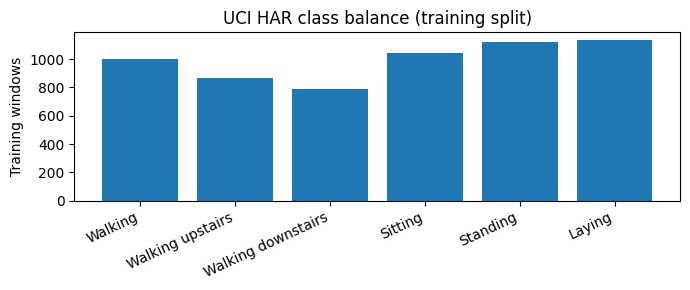

/tmp/ipykernel_807/3905883145.py:31: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  old=pd.concat([old,pd.DataFrame([row])],ignore_index=True)


seed             acc                  f1             params       \
       mean   std      mean       std      mean       std     mean  std   
model                                                                     
GRU    22.0  10.0  0.910304  0.003784  0.911159  0.003714  14790.0  0.0   
LSTM   22.0  10.0  0.888248  0.019052  0.888232  0.019707  19590.0  0.0   
RNN    22.0  10.0  0.817328  0.008286  0.814272  0.007780   5190.0  0.0   

      sec_per_epoch            
               mean       std  
model                          
GRU        0.182078  0.019665  
LSTM       0.158068  0.000438  
RNN        0.170731  0.032973

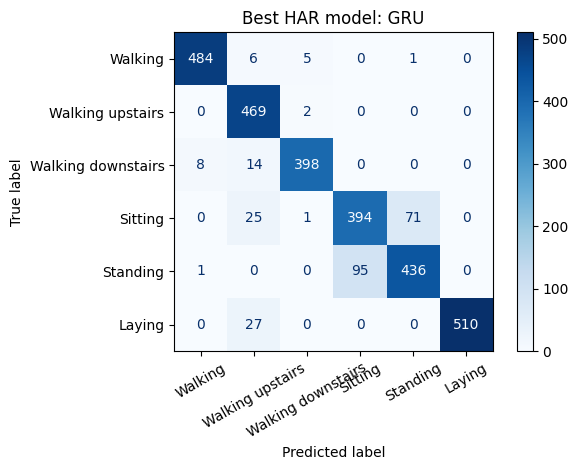

mse_mean   mse_std  solved_runs
model T                                   
GRU   50   0.002282  0.000499            3
      100  0.002139  0.000479            3
      200  0.001983  0.000880            3
      400  0.002421  0.001368            3
LSTM  50   0.005657  0.001801            3
      100  0.119606  0.086687            1
      200  0.168487  0.000098            0
      400  0.153592  0.000043            0
RNN   50   0.172087  0.002829            0
      100  0.170049  0.000381            0
      200  0.168376  0.000256            0
      400  0.153881  0.000287            0

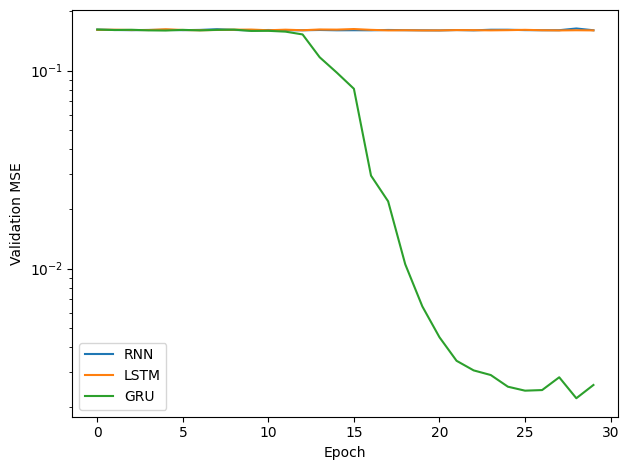

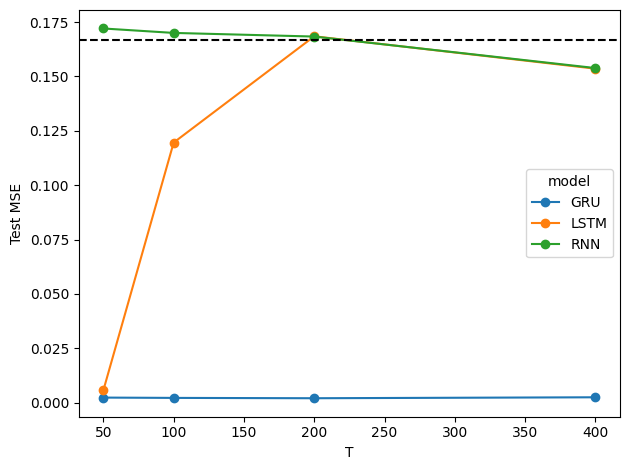

,model,hidden,acc_mean,acc_std,f1_mean,f1_std,params,sec_per_epoch
0,GRU,16,0.885533,0.000518,0.885107,0.001238,1398,0.171341
1,GRU,32,0.889831,0.005958,0.890041,0.005569,4326,0.163123
2,GRU,64,0.900916,0.009997,0.900963,0.010394,14790,0.163054
3,GRU,128,0.891754,0.003342,0.891625,0.003248,54150,0.237984
4,LSTM,16,0.844475,0.048710,0.841447,0.052635,1830,0.177749
5,LSTM,32,0.889040,0.001018,0.889200,0.000849,5702,0.169120
6,LSTM,64,0.888927,0.016597,0.889058,0.017111,19590,0.166333
7,LSTM,128,0.903744,0.010908,0.903625,0.011588,71942,0.373610


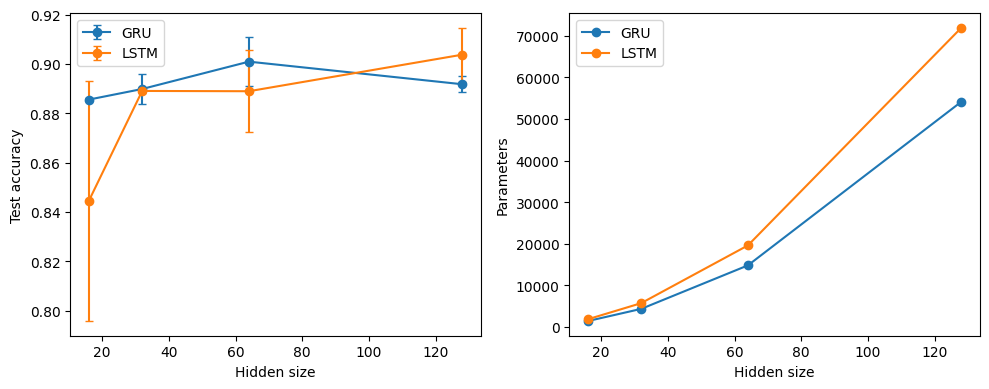

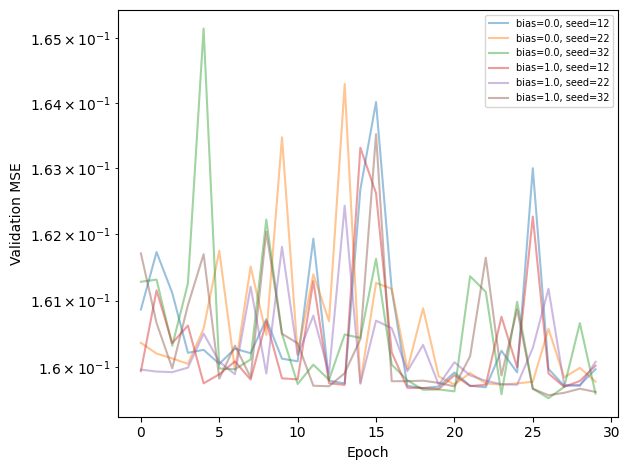

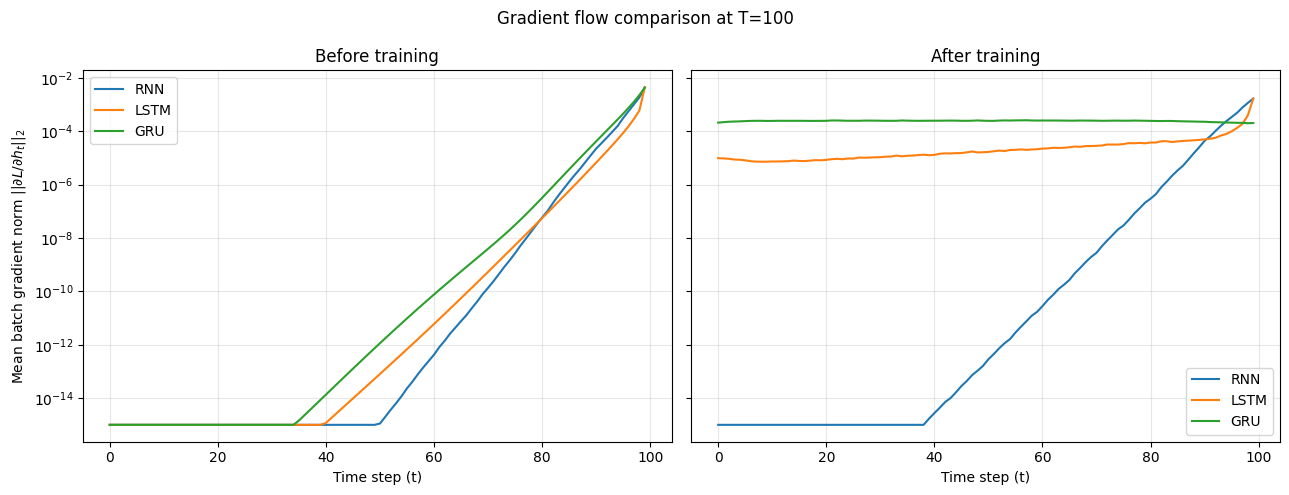

Problem 1 complete. All expected experiment rows were produced.


In [26]:
def run_problem1_complete():
    # Reset only Problem 1 rows so reruns do not duplicate them.
    if RESULTS.exists():
        old=pd.read_csv(RESULTS)
        if len(old): old=old[~old.problem.astype(str).str.startswith('P1')]
        old.to_csv(RESULTS,index=False)
    har=run_har_all()
    adding=run_adding_grid()
    hidden,hidden_summary=run_hidden_size_sweep()
    forget_bias=run_forget_bias_ablation()
    run_gradient_plot()
    assert len(har)==9, 'Expected 3 models x 3 seeds for HAR'
    assert len(adding)==36, 'Expected 4 lengths x 3 models x 3 seeds'
    assert len(hidden)==24, 'Expected 2 models x 4 hidden sizes x 3 seeds'
    assert len(forget_bias)==6, 'Expected 2 forget-bias settings x 3 seeds'
    print('Problem 1 complete. All expected experiment rows were produced.')
    return {'har':har,'adding':adding,'hidden':hidden,'forget_bias':forget_bias}

p1_outputs = run_problem1_complete()

## Reproducibility checklist
Run every experiment cell, verify all assertions, ensure every mandatory figure is written to `problem1/figures`, and confirm that `results.csv` contains all seeds and sequence lengths.